# Telecom Customer Churn Prediction

This project uses machine learning to predict customer churn for a telecommunications company.

The goal is to identify customers who are likely to leave the service and help the business take proactive retention measures.

## 1. Import Libraries

Import the libraries required for data manipulation, visualization, preprocessing, model training, evaluation, handling class imbalance, and model explainability.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

## 2. Load Dataset

Load the original IBM Telco Customer Churn CSV file.

**Expected project layout:** run Jupyter from the `telecom-churn-prediction` project root, with the original CSV stored in the `data/` folder.

In [3]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("\nColumn data types:")
print(df.dtypes)

Dataset shape: (7043, 21)
Total missing values: 0

Column data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


## 3. Data Cleaning

- Convert `TotalCharges` to numeric format.
- Remove rows where `TotalCharges` cannot be converted.
- Remove any previously engineered columns that are not part of this workflow.
- Check for missing values and duplicate records.

In [4]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

df = df.dropna(subset=['TotalCharges'])

df = df.drop(
    ['tenure_group', 'HighValue', 'Churn_binary'],
    axis=1,
    errors='ignore'
)

print("Shape after cleaning:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df['Churn'].value_counts())

print("\nChurn percentage:")
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

Shape after cleaning: (7032, 21)
Missing values remaining: 0
Duplicate rows: 0

Churn distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis (EDA)

Explore the distribution of churn and examine how churn varies across contract types and customer tenure groups. Correlation analysis is also used to inspect relationships between numeric features and churn.

The EDA summaries below are calculated from the cleaned dataset.

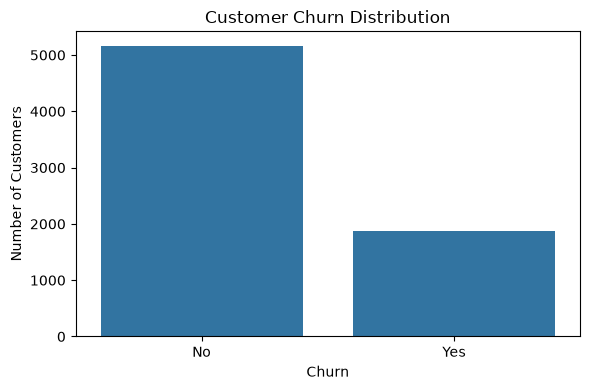

Churn rate by contract type (%):
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64


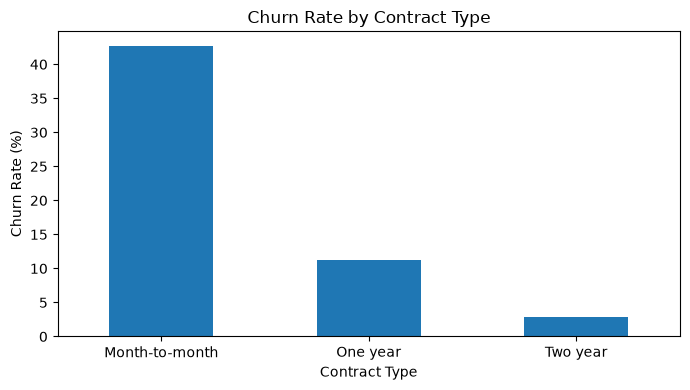


Churn rate by tenure group (%):
tenure_group
New      47.68
Mid      25.54
Loyal    11.93
Name: Churn, dtype: float64


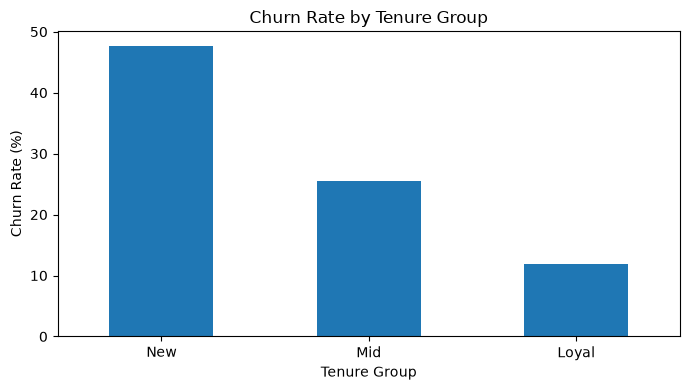


Numeric feature correlations with churn:
tenure           -0.354
TotalCharges     -0.199
SeniorCitizen     0.151
MonthlyCharges    0.193
Name: Churn_binary, dtype: float64


In [5]:
# Overall churn distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# Churn rate by contract type
contract_churn = (
    df.groupby('Contract', observed=False)['Churn']
      .apply(lambda values: (values == 'Yes').mean() * 100)
      .sort_values(ascending=False)
)

print("Churn rate by contract type (%):")
print(contract_churn.round(2))

plt.figure(figsize=(7, 4))
contract_churn.plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Churn rate by tenure group
eda_df = df.copy()
eda_df['tenure_group'] = pd.cut(
    eda_df['tenure'],
    bins=[0, 12, 36, np.inf],
    labels=['New', 'Mid', 'Loyal'],
    include_lowest=True
)

tenure_churn = (
    eda_df.groupby('tenure_group', observed=False)['Churn']
          .apply(lambda values: (values == 'Yes').mean() * 100)
)

print("\nChurn rate by tenure group (%):")
print(tenure_churn.round(2))

plt.figure(figsize=(7, 4))
tenure_churn.plot(kind='bar')
plt.title('Churn Rate by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Correlation with churn
correlation_df = df.copy()
correlation_df['Churn_binary'] = (correlation_df['Churn'] == 'Yes').astype(int)

churn_correlations = (
    correlation_df.select_dtypes(include=np.number)
                  .corr()['Churn_binary']
                  .drop('Churn_binary')
                  .sort_values()
)

print("\nNumeric feature correlations with churn:")
print(churn_correlations.round(3))

## 5. Data Preprocessing

### 5.1 Replace equivalent service categories

Several service columns contain values such as `No internet service` or `No phone service`. These indicate that the customer does not have the corresponding service, so they are grouped with `No` before encoding.

In [6]:
cols_3cat = [
    'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies'
]

df[cols_3cat] = df[cols_3cat].replace(
    {
        'No internet service': 'No',
        'No phone service': 'No'
    }
)

### 5.2 Encode binary categorical columns

Use `LabelEncoder` to convert the binary categorical columns into numeric values. Convert the target column `Churn` into 0 (No) and 1 (Yes).

In [7]:
binary_cols = [
    'gender', 'Partner', 'Dependents', 'PhoneService',
    'PaperlessBilling', 'MultipleLines', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport',
    'StreamingTV', 'StreamingMovies'
]

le = LabelEncoder()

for col in binary_cols:
    df[col] = le.fit_transform(df[col])

df['Churn'] = (df['Churn'] == 'Yes').astype(int)

print(df[binary_cols + ['Churn']].head())

   gender  Partner  Dependents  PhoneService  PaperlessBilling  MultipleLines  \
0       0        1           0             0                 1              0   
1       1        0           0             1                 0              0   
2       1        0           0             1                 1              0   
3       1        0           0             0                 0              0   
4       0        0           0             1                 1              0   

   OnlineSecurity  OnlineBackup  DeviceProtection  TechSupport  StreamingTV  \
0               0             1                 0            0            0   
1               1             0                 1            0            0   
2               1             1                 0            0            0   
3               1             0                 1            1            0   
4               0             0                 0            0            0   

   StreamingMovies  Churn  
0         

### 5.3 One-hot encode remaining categorical features

Use one-hot encoding for `Contract`, `InternetService`, and `PaymentMethod`.

In [8]:
df = pd.get_dummies(
    df,
    columns=['Contract', 'InternetService', 'PaymentMethod'],
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", df.shape)
print("\nRemaining text columns:")
print(df.select_dtypes(include=['object', 'str']).columns.tolist())

Shape after encoding: (7032, 25)

Remaining text columns:
['customerID']


### 5.4 Separate features and target

Remove `customerID` because it is a unique identifier rather than a predictive feature. Keep `Churn` as the target variable.

In [9]:
X = df.drop(['customerID', 'Churn'], axis=1)
y = df['Churn']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

X shape: (7032, 23)
y shape: (7032,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Contract_One year', 'Contract_Two year', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

Target distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64


## 6. Train-Test Split

Split the data into 80% training and 20% testing data. Stratification preserves the original churn-class proportion in both sets.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

X_train: (5625, 23)
X_test: (1407, 23)
y_train: (5625,)
y_test: (1407,)

Training target distribution:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


## 7. Feature Scaling

Standardize the features for Logistic Regression. Fit the scaler on the training data only, then use the fitted scaler to transform the test data.

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (5625, 23)
Scaled testing shape: (1407, 23)


## 8. Model Building

Train three classifiers for comparison:

- Logistic Regression
- Decision Tree
- Random Forest

The Decision Tree and Random Forest use the unscaled feature data. Logistic Regression uses the scaled data.

In [12]:
# 1. Logistic Regression
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)
lr_model.fit(X_train_scaled, y_train)

# 2. Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)
dt_model.fit(X_train, y_train)

# 3. Random Forest
rf_model = RandomForestClassifier(
    random_state=42,
    n_estimators=100
)
rf_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


## 9. Model Evaluation

Evaluate each model on the held-out test set using ROC-AUC and the classification report. Class `1` represents customers who churned.

In [13]:
models = {
    "Logistic Regression": (lr_model, X_test_scaled),
    "Decision Tree": (dt_model, X_test),
    "Random Forest": (rf_model, X_test)
}

for name, (model, X_eval) in models.items():
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]

    print(f"\n{'=' * 50}")
    print(name)
    print(f"{'=' * 50}")

    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))


Logistic Regression
ROC-AUC: 0.8357

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Decision Tree
ROC-AUC: 0.8195

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.84      0.85      1033
           1       0.58      0.60      0.59       374

    accuracy                           0.78      1407
   macro avg       0.72      0.72      0.72      1407
weighted avg       0.78      0.78      0.78      1407


Random Forest
ROC-AUC: 0.8215

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.49      0.55       374

    accurac

### 9.1 Random Forest feature importance

Inspect the top features ranked by the Random Forest's built-in feature-importance scores. These scores describe how the model used features for its splits; they do not establish causation.

In [14]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(10))

                           Feature  Importance
15                    TotalCharges    0.192476
14                  MonthlyCharges    0.178956
4                           tenure    0.173383
18     InternetService_Fiber optic    0.042593
21  PaymentMethod_Electronic check    0.039903
17               Contract_Two year    0.032977
0                           gender    0.028297
13                PaperlessBilling    0.028275
7                   OnlineSecurity    0.023891
16               Contract_One year    0.023426


## 10. Handling Class Imbalance with SMOTE

The target is imbalanced, with fewer churn customers than non-churn customers. Apply SMOTE to the scaled training data only. The test set remains unchanged and is used for evaluation.

In [15]:
smote = SMOTE(random_state=42)

X_train_sm, y_train_sm = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", pd.Series(y_train_sm).value_counts().to_dict())
print("Resampled feature shape:", X_train_sm.shape)

Before SMOTE: {0: 4130, 1: 1495}
After SMOTE: {0: 4130, 1: 4130}
Resampled feature shape: (8260, 23)


### 10.1 Train and evaluate Logistic Regression with SMOTE

Train Logistic Regression on the resampled training data and evaluate it on the original, unresampled test set.

In [16]:
lr_smote = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr_smote.fit(X_train_sm, y_train_sm)

y_pred_sm = lr_smote.predict(X_test_scaled)
y_prob_sm = lr_smote.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression + SMOTE")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_sm):.4f}")

print(classification_report(
    y_test,
    y_pred_sm,
    target_names=["No Churn", "Churn"]
))

Logistic Regression + SMOTE
ROC-AUC: 0.8340
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1033
       Churn       0.50      0.78      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.75      1407



### 10.2 Confusion matrix

Visualize the SMOTE model's test-set predictions and save the image for the project README.

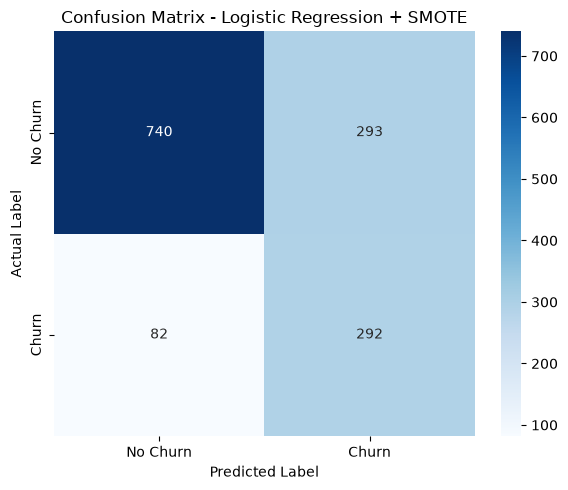

In [29]:
Path("images").mkdir(exist_ok=True)

cm = confusion_matrix(y_test, y_pred_sm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)
plt.title('Confusion Matrix - Logistic Regression + SMOTE')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig('../images/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

## 11. Cross-Validation

Use stratified 5-fold cross-validation to assess how consistently the Logistic Regression + SMOTE workflow performs across different training and validation folds.

The imbalanced-learn pipeline ensures that scaling and SMOTE are fitted/applied within each training fold, avoiding data leakage into that fold's validation data.

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(
        random_state=42,
        max_iter=1000
    ))
])

cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("Cross-validation ROC-AUC scores:")
print(cv_scores.round(4))

print(f"Mean: {cv_scores.mean():.4f}")
print(f"Std: {cv_scores.std():.4f}")
print(f"Range: {cv_scores.min():.4f} – {cv_scores.max():.4f}")

Cross-validation ROC-AUC scores:
[0.8428 0.8427 0.8391 0.8506 0.8538]
Mean: 0.8458
Std: 0.0055
Range: 0.8391 – 0.8538


## 12. Model Explainability with SHAP

Use SHAP to understand how features contribute to the Logistic Regression + SMOTE model's predictions.

The summary plot shows feature contributions across the test set. Positive SHAP values push the model output toward the churn class; negative values push it away from churn. The displayed feature values for encoded categorical columns should be interpreted with care.

In [19]:
explainer = shap.LinearExplainer(
    lr_smote,
    X_train_sm
)

shap_values = explainer.shap_values(X_test_scaled)

Background dataset has 8260 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=8260 when initializing the masker.


### 12.1 SHAP summary plot

Generate the SHAP summary plot and save it for the project README.

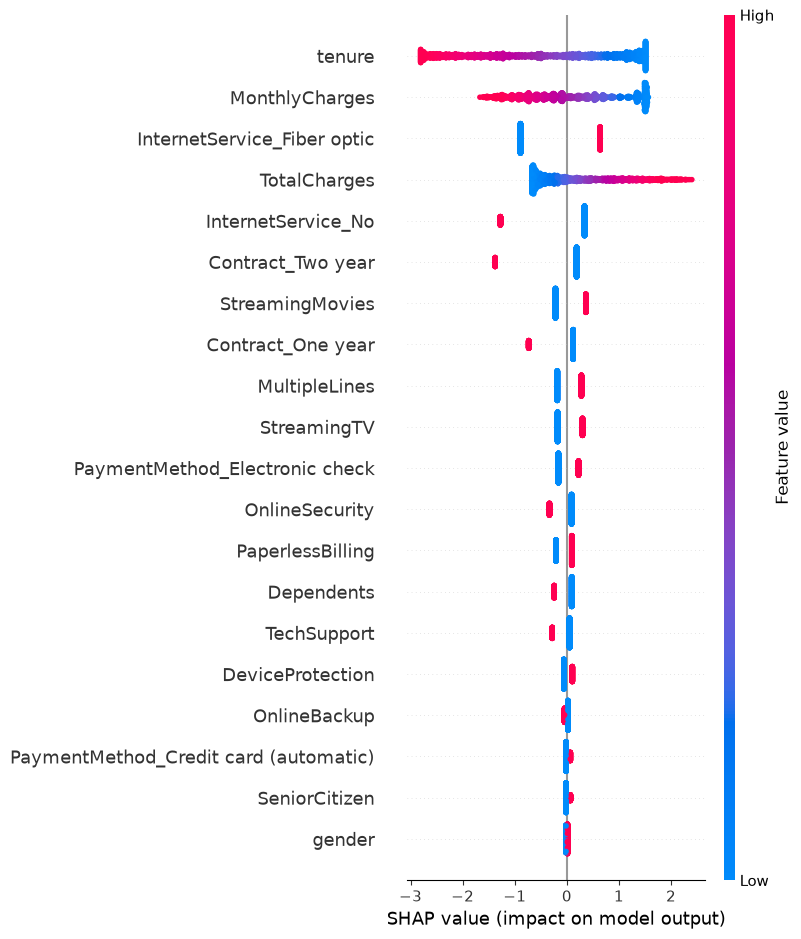

In [30]:
Path("images").mkdir(exist_ok=True)

shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=X.columns.tolist(),
    show=False
)

plt.savefig('../images/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

### 12.2 Explain one test prediction with a waterfall plot

Inspect the feature contributions for the first row in the test set. This is test-set row 0, not necessarily the first row in the original CSV.

Explaining prediction for test customer 0:
Actual: 0
Predicted: 0


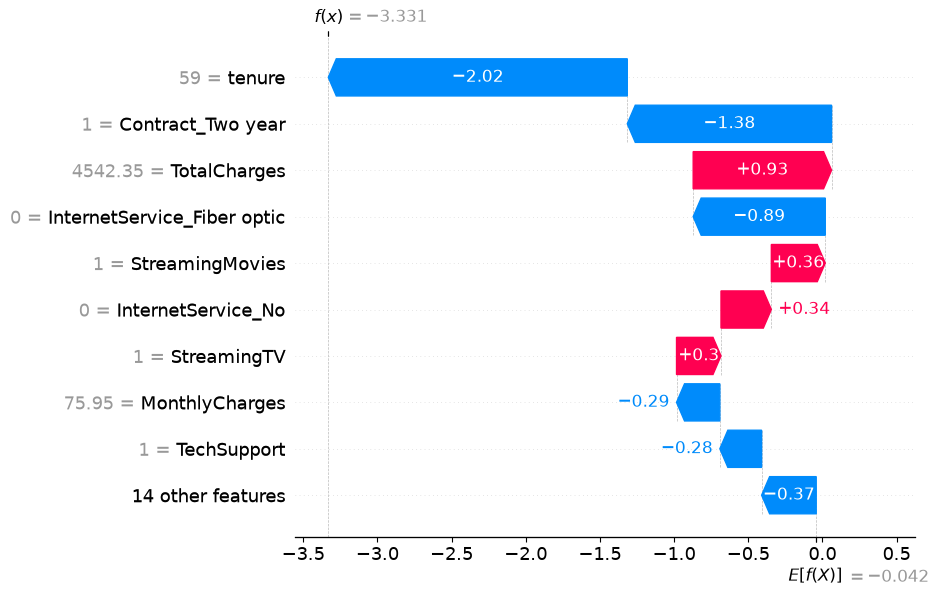

In [21]:
print("Explaining prediction for test customer 0:")
print("Actual:", y_test.iloc[0])
print("Predicted:", y_pred_sm[0])

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test.iloc[0].values,
        feature_names=X.columns.tolist()
    ),
    max_display=10
)

## 13. Final Model Selection

**Selected model:** Logistic Regression with SMOTE

### Why this model?

- Logistic Regression achieved the highest ROC-AUC (**0.8357**) among the three original models tested.
- After applying SMOTE, churn recall increased from **57% to 78%**, helping identify more customers who actually churned.
- The SMOTE model achieved a test ROC-AUC of **0.8340**, which is close to the original Logistic Regression ROC-AUC of 0.8357. SMOTE therefore improved recall at the default classification threshold, but did not improve ranking performance.
- Five-fold cross-validation on the training data produced a mean ROC-AUC of **0.8458** with a standard deviation of **0.0055**, indicating consistent scores across the five folds.
- Logistic Regression is a relatively simple and interpretable model. Its performance may be related to approximately linear relationships in some important features, but this has not been conclusively established.

### Test-set model comparison

| Model | ROC-AUC | Churn precision | Churn recall | Churn F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.8357 | 0.65 | 0.57 | 0.61 |
| Decision Tree | 0.8195 | 0.58 | 0.60 | 0.59 |
| Random Forest | 0.8215 | 0.62 | 0.49 | 0.55 |
| Logistic Regression + SMOTE | 0.8340 | 0.50 | 0.78 | 0.61 |

### Key business insight

A telecom company may prioritize **recall** when identifying customers at risk of churn if missing a likely churner is more costly than contacting a customer who would have stayed.

The SMOTE model achieved **78% churn recall** and **50% churn precision**. This means it identifies more actual churners, but it also flags more customers who would not churn. The business should weigh this trade-off against the cost and effectiveness of retention offers.

### Limitations

- Decision Tree and Random Forest were not extensively hyperparameter-tuned.
- SMOTE shifted the precision-recall trade-off but did not improve ROC-AUC. Class weighting or decision-threshold tuning could potentially produce a similar shift.
- No business cost model was used to quantify false-positive and false-negative costs.
- The model was evaluated on one held-out test split from a single dataset.
- The encoded categorical features require careful interpretation in SHAP explanations.

### Conclusion

Logistic Regression with SMOTE is selected as the current model because its higher churn recall aligns with the project's objective of identifying more customers at risk of leaving. Cross-validation shows consistent ROC-AUC across the five folds. Further threshold tuning and business-cost evaluation would be needed before using the model in a real customer-retention system.